# LAB 7: ANN on MNIST Dataset

## Overview
This notebook is organized into clear labeled sections to make the code easier to follow without changing the original logic.

### Section guide
1. Imports and setup
2. Dataset loading and preprocessing
3. Model training
4. Results and evaluation


In [1]:
import tensorflow

In [2]:
from tensorflow.keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [3]:
train_images[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [4]:
from PIL import Image

In [5]:
im = Image.fromarray(train_images[0])
im

In [6]:
from tensorflow.keras import models,layers

model = models.Sequential()   

model.add(layers.Dense(512, activation='relu', input_shape=(28*28,)))

model.add(layers.Dense(10, activation='softmax'))

C:\Users\A.S Computers\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
train_images= train_images.reshape((60000, 784))                                    
train_images = train_images.astype("float32") / 255


test_images = test_images.reshape((10000, 784))
test_images = test_images.astype("float32") / 255

In [8]:
# Converts a class vector (integers) to binary class matrix
from tensorflow.keras.utils import to_categorical     
test_labels_by_cat  = to_categorical(test_labels)
train_labels_by_cat  = to_categorical(train_labels)

In [9]:
model.compile(optimizer="rmsprop",loss="categorical_crossentropy",metrics=["accuracy"])

In [10]:
model.fit(train_images, train_labels_by_cat, epochs=5, batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9236 - loss: 0.2638
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9692 - loss: 0.1071
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9800 - loss: 0.0696
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9865 - loss: 0.0489
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9907 - loss: 0.0354


In [11]:
train_labels

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,102 (3.11 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 407,052 (1.55 MB)

In [13]:
test_loss, test_acc = model.evaluate(test_images, test_labels_by_cat)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9790 - loss: 0.0671


In [14]:
import numpy as np
np.argmax(model.predict(test_images[[0]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


np.int64(7)

In [15]:
test_labels[0]

np.uint8(7)

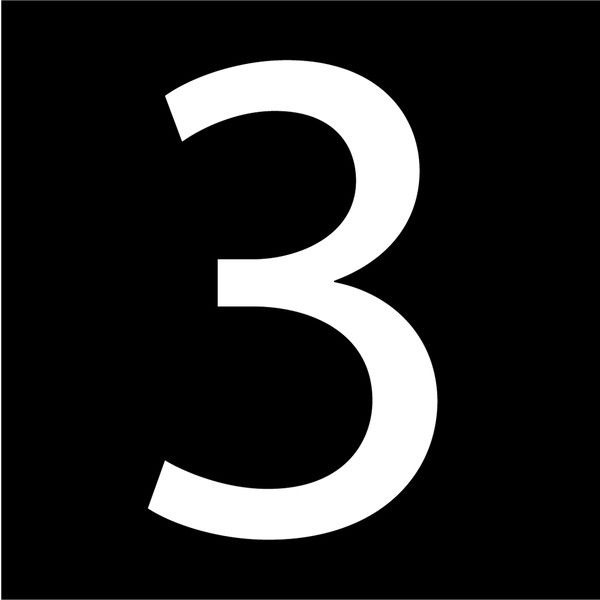

In [16]:
three = Image.open('three.jpeg')
three

In [17]:
# Convert image to grayScale
image = three.convert("L")

# Save the grayscale image
image.save("grayscale_three.jpg")

In [18]:
eight_grey = Image.open('grayscale_three.jpg')

# convert image to vector or matrix 
arr = np.asarray(eight_grey)

In [19]:
eight_grey = Image.open('grayscale_three.jpg').resize((28, 28))

# convert image to vector or matrix 
arr = np.asarray(eight_grey)
# Reshape to 2D batch format required by the model
arr = arr.reshape((1, 784))

In [20]:
p = model.predict(arr)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step


In [21]:
np.argmax(p)

np.int64(3)

In [22]:
p = model.predict(np.asarray(Image.open('grayscale_three.jpg').resize((28, 28))).reshape(1, 784))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
